In [13]:

import pandas as pd                 
import numpy as np 
import matplotlib.pyplot as plt    
import seaborn as sns              
import warnings



df = pd.read_csv('insurance.csv')

print(df.shape)     
df.head()         


(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [14]:
df.info()           

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [15]:
df.describe()      


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<Axes: xlabel='charges', ylabel='Count'>

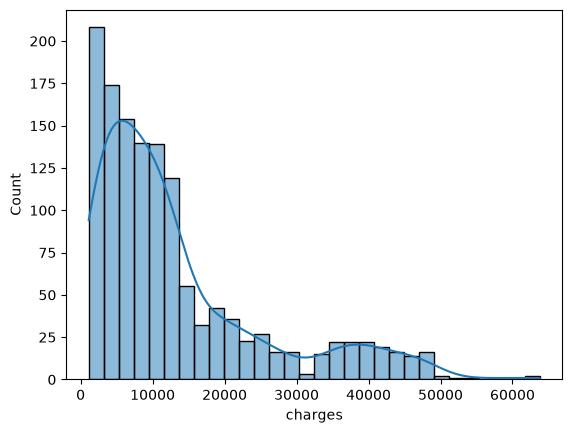

In [16]:


sns.histplot(df['charges'], kde=True)    

<Axes: xlabel='charges'>

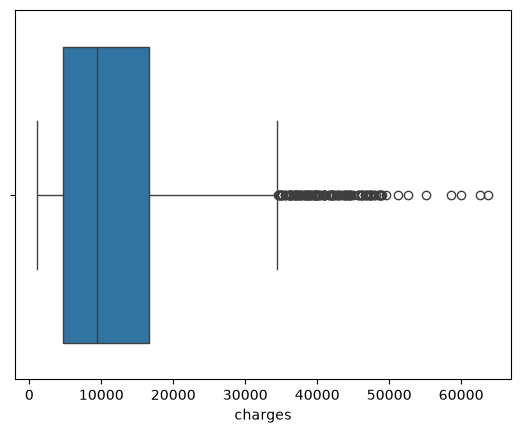

In [17]:
sns.boxplot(x=df['charges']) 


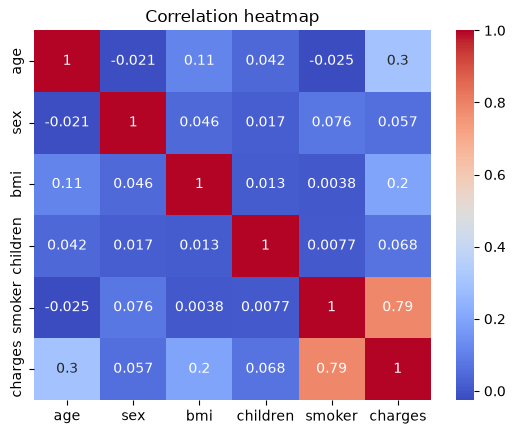

In [18]:

df_num = df.copy()
df_num['sex'] = df_num['sex'].map({'female': 0, 'male': 1})
df_num['smoker'] = df_num['smoker'].map({'no': 0, 'yes': 1})


sns.heatmap(df_num[['age','sex','bmi','children','smoker','charges']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

 Clean the data

In [19]:
print('Missing values in each column:')
print(df.isnull().sum())

print('Duplicate rows:', df.duplicated().sum())

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


In [20]:
# Remove duplicate rows
df = df.drop_duplicates()
print('New shape:', df.shape)

New shape: (1337, 7)


In [21]:
# Are the category names clean?
print(df['sex'].unique())
print(df['smoker'].unique())
print(df['region'].unique())



<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str
<ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [22]:
# Are the numbers sensible?
print('Age:', df['age'].min(), 'to', df['age'].max())
print('BMI:', df['bmi'].min(), 'to', df['bmi'].max())
print('Children:', df['children'].min(), 'to', df['children'].max())
print('Smallest charge:', df['charges'].min())

Age: 18 to 64
BMI: 15.96 to 53.13
Children: 0 to 5
Smallest charge: 1121.8739


In [23]:
# IQR method: a value is an outlier if it is far outside the middle 50% of data
for col in ['age', 'bmi', 'charges']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(col, '-> number of outliers:', len(outliers))

age -> number of outliers: 0
bmi -> number of outliers: 9
charges -> number of outliers: 139


In [24]:
# Who are the people with very high charges?
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
upper = Q3 + 1.5 * (Q3 - Q1)
high = df[df['charges'] > upper]
print(high['smoker'].value_counts())

smoker
yes    136
no       3
Name: count, dtype: int64


In [25]:
# sex and smoker have 2 values -> change to 0 and 1
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})

df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


In [26]:
# BMI categories (using official BMI ranges)
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, 100],
                            labels=['Underweight', 'Normal', 'Overweight', 'Obese'])

# Age groups
df['age_group'] = pd.cut(df['age'], bins=[17, 29, 44, 59, 100],
                         labels=['18-29', '30-44', '45-59', '60+'])

# Average charges for each smoker / BMI category
print(df.groupby(['smoker', 'bmi_category'])['charges'].mean().round())

smoker  bmi_category
0       Underweight      5485.0
        Normal           7735.0
        Overweight       8226.0
        Obese            8866.0
1       Underweight     18810.0
        Normal          19942.0
        Overweight      22491.0
        Obese           41693.0
Name: charges, dtype: float64


In [27]:
# New number columns
df['obese'] = (df['bmi'] >= 30).astype(int)       
df['smoker_obese'] = df['smoker'] * df['obese']   
df['smoker_bmi'] = df['smoker'] * df['bmi']     
df['smoker_age'] = df['smoker'] * df['age']      


df = pd.get_dummies(df, columns=['bmi_category', 'age_group'], drop_first=True, dtype=int)

df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,obese,smoker_obese,smoker_bmi,smoker_age,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,age_group_30-44,age_group_45-59,age_group_60+
0,19,0,27.900,0,1,16884.92400,0,0,1,0,0,27.9,19,0,1,0,0,0,0
1,18,1,33.770,1,0,1725.55230,0,1,0,1,0,0.0,0,0,0,1,0,0,0
2,28,1,33.000,3,0,4449.46200,0,1,0,1,0,0.0,0,0,0,1,0,0,0
3,33,1,22.705,0,0,21984.47061,1,0,0,0,0,0.0,0,1,0,0,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0,0,0,0.0,0,0,1,0,1,0,0


In [28]:
# Which columns are most related to charges?
print(df.corr()['charges'].sort_values(ascending=False).round(2))

charges                    1.00
smoker_bmi                 0.85
smoker_obese               0.81
smoker_age                 0.79
smoker                     0.79
age                        0.30
age_group_60+              0.20
bmi_category_Obese         0.20
obese                      0.20
bmi                        0.20
age_group_45-59            0.15
region_southeast           0.07
children                   0.07
sex                        0.06
region_northwest          -0.04
age_group_30-44           -0.04
region_southwest          -0.04
bmi_category_Normal       -0.11
bmi_category_Overweight   -0.12
Name: charges, dtype: float64


**Feature selection:** `smoker_bmi`, `smoker_obese`, `smoker_age`, `smoker` and `age` are the strongest. `sex` and `region` columns are weak, but we keep them and let the model decide (we check importance at the end).

In [29]:
from sklearn.model_selection import train_test_split

X = df.drop('charges', axis=1)   
y = df['charges']               

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 1069
Testing rows: 268


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)         

In [31]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Put the 4 models in a dictionary
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

before_results = []   # empty list to store the scores

for name, model in models.items():
    model.fit(X_train_scaled, y_train)            # train
    pred = model.predict(X_test_scaled)           # predict on test data

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    before_results.append([name, mae, mse, rmse, r2])

before_df = pd.DataFrame(before_results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])
before_df.round(3)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,2261.412,1.689708e+07,4110.606,0.908
1,Ridge,2260.060,1.687433e+07,4107.838,0.908
2,Random Forest,2666.411,2.239129e+07,4731.943,0.878
3,Gradient Boosting,2493.689,1.851056e+07,4302.389,0.899


These are the scores **before tuning**.

In [32]:
from sklearn.model_selection import GridSearchCV

ridge_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}
ridge_search = GridSearchCV(Ridge(), ridge_grid, cv=5, scoring='neg_root_mean_squared_error')
ridge_search.fit(X_train_scaled, y_train)
print('Best Ridge settings:', ridge_search.best_params_)

Best Ridge settings: {'alpha': 1}


In [33]:

rf_grid = {
    'n_estimators': [100, 300],        # number of trees
    'max_depth': [3, 5, 7],            # how deep each tree can go
    'min_samples_leaf': [5, 10, 20]    # minimum people in a leaf
}
rf_search = GridSearchCV(RandomForestRegressor(random_state=42), rf_grid, cv=5, scoring='neg_root_mean_squared_error')
rf_search.fit(X_train_scaled, y_train)
print('Best Random Forest settings:', rf_search.best_params_)

Best Random Forest settings: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}


In [34]:

gb_grid = {
    'n_estimators': [100, 300],
    'learning_rate': [0.03, 0.1],
    'max_depth': [1, 2, 3]
}
gb_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_grid, cv=5, scoring='neg_root_mean_squared_error')
gb_search.fit(X_train_scaled, y_train)
print('Best Gradient Boosting settings:', gb_search.best_params_)

Best Gradient Boosting settings: {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 300}


In [35]:
# The tuned models
tuned_models = {
    'Linear Regression': models['Linear Regression'],   # nothing to tune
    'Ridge': ridge_search.best_estimator_,
    'Random Forest': rf_search.best_estimator_,
    'Gradient Boosting': gb_search.best_estimator_
}

after_results = []
for name, model in tuned_models.items():
    pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)
    after_results.append([name, mae, mse, rmse, r2])

after_df = pd.DataFrame(after_results, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])

# Put before and after side by side
compare = before_df.merge(after_df, on='Model', suffixes=('_before', '_after'))
compare[['Model', 'MAE_before', 'MAE_after', 'RMSE_before', 'RMSE_after', 'R2_before', 'R2_after']].round(3)

,Model,MAE_before,MAE_after,RMSE_before,RMSE_after,R2_before,R2_after
0,Linear Regression,2261.412,2261.412,4110.606,4110.606,0.908,0.908
1,Ridge,2260.060,2260.060,4107.838,4107.838,0.908,0.908
2,Random Forest,2666.411,2387.148,4731.943,4249.006,0.878,0.902
3,Gradient Boosting,2493.689,2421.517,4302.389,4222.960,0.899,0.903


In [36]:
from sklearn.model_selection import cross_val_score

cv_scores = {}
for name, model in tuned_models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_scores[name] = -scores.mean()          # make it positive RMSE
    print(name, '-> CV RMSE:', round(cv_scores[name]))

best_name = min(cv_scores, key=cv_scores.get)   # model with the smallest error
best_model = tuned_models[best_name]
print()
print('Best model:', best_name)

Linear Regression -> CV RMSE: 4478
Ridge -> CV RMSE: 4468
Random Forest -> CV RMSE: 4600
Gradient Boosting -> CV RMSE: 4546

Best model: Ridge


In [37]:
# FINAL TEST on the untouched test data
final_pred = best_model.predict(X_test_scaled)

print('Final MAE :', round(mean_absolute_error(y_test, final_pred), 2))
print('Final MSE :', round(mean_squared_error(y_test, final_pred), 2))
print('Final RMSE:', round(np.sqrt(mean_squared_error(y_test, final_pred)), 2))
print('Final R2  :', round(r2_score(y_test, final_pred), 3))

Final MAE : 2260.06
Final MSE : 16874332.12
Final RMSE: 4107.84
Final R2  : 0.908


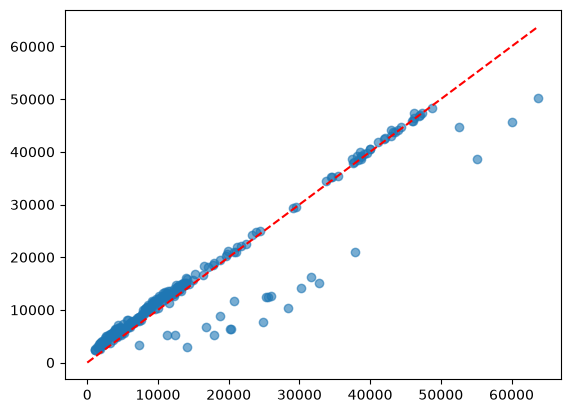

In [38]:

plt.scatter(y_test, final_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--')



<Axes: xlabel='charges', ylabel='Count'>

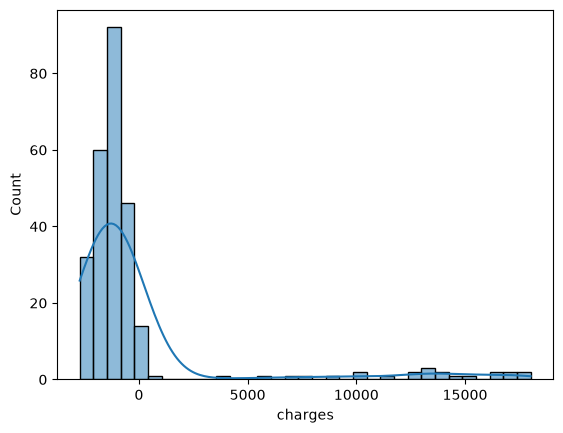

In [39]:
errors = y_test - final_pred
sns.histplot(errors, kde=True)